# Proyek Analisis Segmentasi Pelanggan: Distribusi Norton

**Studi kasus:** memetakan basis pelanggan subscription Norton Indonesia dari data transaksi (cobrand Telkomsel, Digiflazz, retail) menjadi segmen yang actionable.

Dokumen ini memenuhi 4 kompetensi mata kuliah: (1) konsep analisis segmentasi dan identifikasi proses bisnis; (2) pemilihan metode dan pendekatan; (3) penggunaan bahasa dan tools; (4) perancangan workflow segmentasi.

## Bab 1. Konsep Dasar Analisis Segmentasi Pelanggan

### 1.1 Definisi dan tipe segmentasi

**Segmentasi pelanggan** adalah proses membagi pasar atau basis pelanggan menjadi kelompok yang relatif homogen berdasarkan karakteristik tertentu, agar strategi pemasaran dapat diarahkan per kelompok. Empat tipe umum:

| Tipe | Basis | Bisa diterapkan pada data ini? |
|---|---|---|
| **Demografi** | usia, gender, pendapatan, pendidikan | Tidak. Master pelanggan tidak ada, hanya `customer_id` anonim |
| **Geografis** | kota, provinsi, negara | Tidak. Tidak ada atribut lokasi pelanggan (hanya IP sebagian kecil) |
| **Perilaku** | riwayat transaksi, frekuensi, nilai, churn, perangkat | **Ya**. Kolom lengkap: harga, durasi, status, perangkat, kanal |
| **Psikografis** | gaya hidup, nilai | Sebagian. Hanya proksi lemah lewat preferensi perangkat dan paket |

Keputusan jujur: proyek ini menerapkan **segmentasi berbasis perilaku**, karena itu satu-satunya dimensi yang tersedia dan terbilang kuat di data.

### 1.2 Identifikasi proses bisnis

Dari analisis proyek Basis Data: pelanggan membeli paket Norton melalui kanal (Telkomsel, Digiflazz, retail), melakukan redem, dan melewati lifecycle langganan (mulai, aktif, berakhir, batal). Karakteristik per perilaku yang bisa diukur per pelanggan: jumlah transaksi, total pengeluaran, selang transaksi terakhir (recency), durasi langganan rata-rata, riwayat pembatalan, preferensi harga, kanal, dan perangkat.

### 1.3 Tahapan segmentasi dan pemanfaatannya

Tahapan: (1) tujuan bisnis, (2) pilih basis dan variabel, (3) pengumpulan dan pembersihan data, (4) memberdayakan variabel (feature engineering), (5) segmentasi (clustering), (6) profiling dan validasi, (7) evaluasi dan strategi. Pemanfaatan segmen: targeting, positioning, personalisasi promosi, strategi retensi dan upsell.

## Bab 2. Metode dan Pendekatan

### 2.1 Kerangka RFM

RFM memotret nilai pelanggan dari tiga sudut:

| Komponen | Pertanyaan | Variabel di sini |
|---|---|---|
| Recency (R) | Berapa lama sejak transaksi terakhir? | `recency_days` |
| Frequency (F) | Seberapa sering bertransaksi? | `n_valid` (order yang valid) |
| Monetary (M) | Berapa total pengeluaran? | `total_spend` (harga order valid) |

RFM diskalakan ke skor 1-5 tiap komponen (kuintil), dan skor gabungan `rfm_score = R*100 + F*10 + M`.

### 2.2 Clustering K-Means

**Mengapa K-Means:** fitur perilaku numerik kontinu, jumlah klaster tidak diketahui sebelumnya, interpretasi lewat pusat klaster mudah, dan sudah menjadi standar untuk segmentasi RFM. Perbandingan dengan pendekatan rule-based (tiering nilai manual) disajikan sebagai alternatif; K-Means dipilih karena menemukan pola kombinasi fitur (misal nilai rendah tapi frekuensi tinggi) yang luput dari tiering tunggal.

**Jumlah klaster:** dievaluasi lewat kurva elbow (inertia) dan silhouette. Hasil nyata: silhouette maksimum di **k=2** yang hanya memisahkan segmen premium kecil (146 vs 9.178), tidak actionable. Keputusan metode: dipilih **k=4** dengan alasan diameter: kurva elbow melandai setelah k=4-5 dan silhouette k=4 (0,597) hampir setinggi k=5 (0,600), empat segmen lebih mudah diinterpretasi untuk strategi. Keputusan ini dicatat transparan, bukan menyembunyikan bahwa k=2 adalah optimum statistik.

### 2.3 Fitur yang dipakai (ternormalisasi)

`recency_days, n_valid, total_spend, avg_price, cancel_share, avg_duration_days` — diskalakan dengan StandardScaler agar bobot antarfitur setara.

In [1]:
import os
import sqlite3
import sys

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.join(os.path.abspath("."), "scripts"))
import etl_features as fx
import clustering as cl
import charts as ch

BASE = os.path.abspath(".")
DB = os.path.join(BASE, "segmentasi.db")
DATA = os.path.join(BASE, "data")
SCHEMA = os.path.join(BASE, "sql", "segment_schema.sql")
OUT = os.path.join(BASE, "assets")

### 2.4 Feature engineering per pelanggan

Input: 9.326 pelanggan dari log transaksi (14.261 baris, baris uji dikeluarkan).

In [2]:
feats = fx.build_features(DB, DATA, SCHEMA)
print("jumlah pelanggan:", len(feats))
feats[["customer_id", "n_valid", "total_spend", "recency_days",
       "cancel_share", "avg_duration_days"]].head(8).to_string(index=False)

jumlah pelanggan: 9324


'                         customer_id  n_valid  total_spend  recency_days  cancel_share  avg_duration_days\n0004085d-bdcc-45c4-b239-0bc7f9138c33        1        15000          24.0           0.0               30.0\n00117e44-354d-46ea-aa4f-713c3c6d5dfd        1        15000           4.0           0.0               30.0\n0022b10f-1514-4437-a06f-cb3703395258        2        22000          29.0           0.5               45.0\n00253833-79ba-40c4-9483-ae87ce5939dc        1        11000           0.0           0.0               30.0\n002c78d6-dd27-4801-9b33-32c2da03dd3f        2        30000          47.0           0.5               45.0\n00308ec8-a789-4278-8c44-fca8e141b39f        1        11000           2.0           0.0               30.0\n00322898-08ce-47f6-9bfa-c5176008b999        2        30000          33.0           0.5               45.0\n0038b215-21ec-46e4-9872-cafc9981eaca        1        11000          29.0           0.0               30.0'

In [3]:
feats[["n_valid", "total_spend", "recency_days", "avg_price",
       "cancel_share", "avg_duration_days"]].describe().round(2).to_string()

'       n_valid  total_spend  recency_days  avg_price  cancel_share  avg_duration_days\ncount  9324.00      9324.00        9323.0    9324.00       9324.00            9323.00\nmean      1.53     23086.75          29.3   15774.62          0.25              42.05\nstd       1.14     27889.63          17.0   21021.13          0.28              40.82\nmin       0.00         0.00           0.0       0.00          0.00              29.00\n25%       1.00     11000.00          20.0   11000.00          0.00              30.00\n50%       1.00     15000.00          30.0   13000.00          0.00              30.00\n75%       2.00     30000.00          41.0   15000.00          0.50              45.00\nmax      65.00    975000.00         323.0  500000.00          1.00             824.00'

## Bab 3. Implementasi

### 3.1 RFM scoring

In [4]:
rfm = cl.compute_rfm(feats)
rfm.describe().round(2).to_string()

'       r_score  f_score  m_score  rfm_score\ncount  9324.00  9324.00  9324.00    9324.00\nmean      3.00     3.00     3.00     333.00\nstd       1.41     1.41     1.41     134.83\nmin       1.00     1.00     1.00     111.00\n25%       2.00     2.00     2.00     232.00\n50%       3.00     3.00     3.00     333.00\n75%       4.00     4.00     4.00     433.00\nmax       5.00     5.00     5.00     555.00'

In [5]:
print("Distribusi skor RFM gabungan (rfm_score):")
rfm["rfm_score"].value_counts().sort_index().to_string()

Distribusi skor RFM gabungan (rfm_score):


'rfm_score\n111     93\n112     33\n113      9\n114      2\n115      4\n121     44\n122     73\n123     30\n124      1\n125      4\n132     94\n133     53\n134     86\n141      1\n143    252\n144    394\n151      1\n152      1\n153     40\n154    168\n155    482\n211    140\n212     21\n213      6\n215      4\n221     55\n222     93\n223     22\n225      5\n231     24\n232    112\n233     64\n234     64\n235      3\n241     28\n242      1\n243    193\n244    405\n251     24\n253     32\n254    160\n255    409\n311    198\n312    146\n313     40\n315      2\n321     77\n322    137\n323    157\n325      6\n331     33\n332    130\n333    177\n334     59\n335      5\n341     22\n342      2\n343    116\n344    250\n345      1\n351     13\n352      1\n353     19\n354     71\n355    202\n411    296\n412    174\n413     44\n415     19\n421    131\n422    158\n423    221\n425     26\n431     75\n432    173\n433    160\n434     29\n435     38\n441      6\n442      3\n443     22\n444    128\n445 

### 3.2 Evaluasi jumlah klaster (elbow + silhouette)

In [6]:
_, X = cl.prepare_matrix(feats)
m = cl.elbow_and_silhouette(X, kmax=9)
print("Keputusan: k=4 (alasan pada Bab 2.2; k=2 optimum statistik tapi tidak actionable)")
m.to_string(index=False)

Keputusan: k=4 (alasan pada Bab 2.2; k=2 optimum statistik tapi tidak actionable)


' k      inertia  silhouette\n 2 36284.317123    0.842264\n 3 22200.936674    0.595360\n 4 14647.765426    0.596525\n 5 12416.789124    0.600178\n 6 10778.027654    0.530718\n 7  8550.116853    0.538072\n 8  7209.616849    0.548197\n 9  6048.696229    0.576509'

In [7]:
K = 4
res = cl.run_clustering(feats, K)
labels = res["labels"]
print("PCA 2 komponen: varians tercakup", [round(v, 3) for v in res["explained"]])
print("banyak pelanggan per klaster:")
pd.Series(labels).value_counts().sort_index().to_string()

PCA 2 komponen: varians tercakup [0.456, 0.773]
banyak pelanggan per klaster:


'0    4954\n1    4228\n2     140\n3       2'

### 3.3 Profil segmen hasil clustering

In [8]:
prof = cl.profile_clusters(feats, labels, K)
prof.to_string(index=False)

' cluster_id    n  mean_recency_days  mean_freq  mean_spend  avg_price  cancel_share  churn_ever_share  premium_share  mean_duration top_channel dominant_platform\n          0 4954               21.0       1.01     13945.0    13671.0         0.000             0.000          0.089           30.2        TSEL           Android\n          1 4228               39.5       2.12     28617.0    13430.0         0.542             0.584          0.010           45.5        TSEL           Android\n          2  140               14.1       1.04    166486.0   161029.0         0.007             0.014          0.986          348.3        TSEL           Android\n          3    2              118.5      62.50    937500.0    15000.0         0.903             1.000          0.000          632.3   DIGIFLAZZ           Windows'

In [9]:
cl.save_results(DB, feats, labels, prof, rfm)
print("hasil segmen disimpan ke segmentasi.db (seg_cluster, seg_assignment)")

hasil segmen disimpan ke segmentasi.db (seg_cluster, seg_assignment)


### 3.4 Interpretasi segmen (penamaan)

| Segmen | Deskripsi dari angka |
|---|---|
| **0. Pembeli Baru Aktif** | 4.954 pelanggan, 1 transaksi bersih, tanpa riwayat batal (churn 0%), harga menengah, durasi 30 hari |
| **1. Pembeli Rentan Churn** | 4.228 pelanggan, frekuensi 2x, setengah riwayatnya CANCEL (54%), nilai Rp 28,6 rb |
| **2. Pembeli Premium** | 140 pelanggan, spend rata-rata Rp 166 rb, 98,6% kelas premium, durasi 348 hari |
| **3. Pelaku Berulang Ekstrem** | 2 pelanggan, 60-65 transaksi, kanal Digiflazz, windows; pola reseller/bulk, perlu kontrol anomali |

Rekon numerik: 4.954 + 4.228 + 140 + 2 = **9.324** pelanggan tersegmen.

### elbow.png


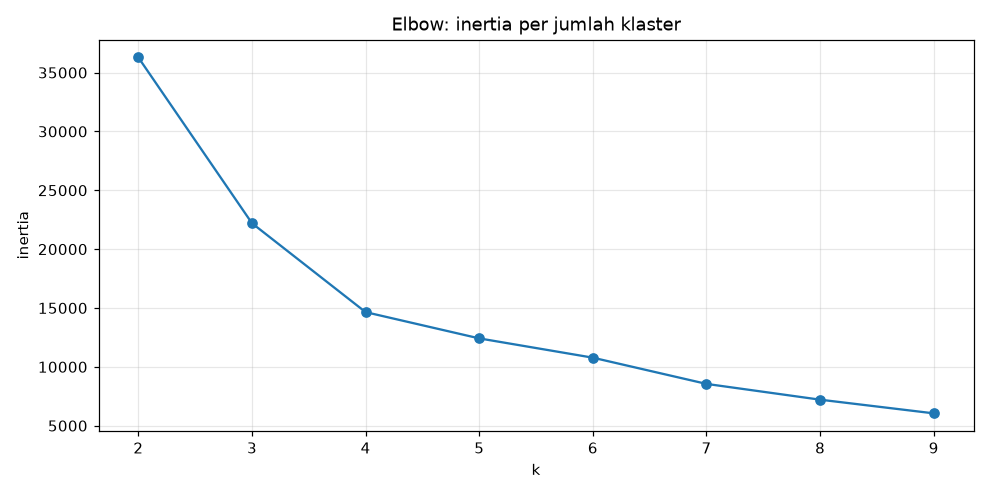

### silhouette.png


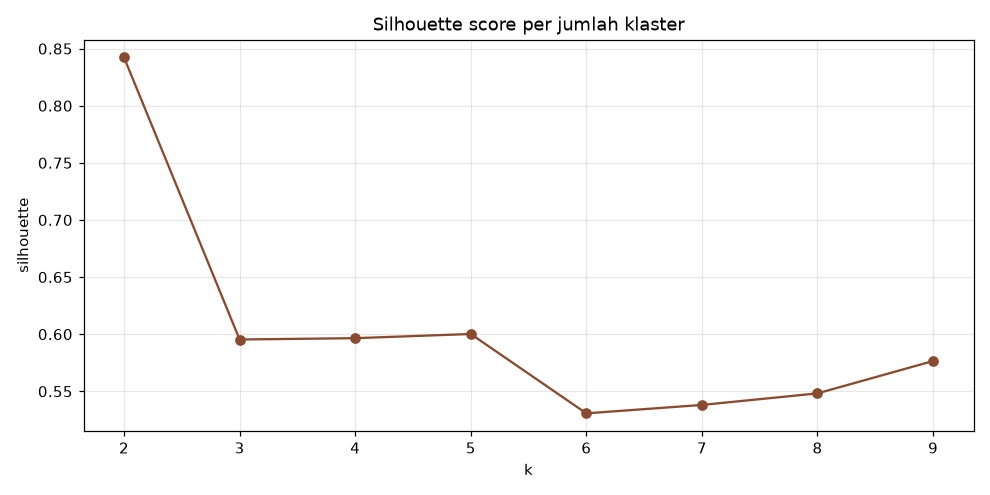

### pca.png


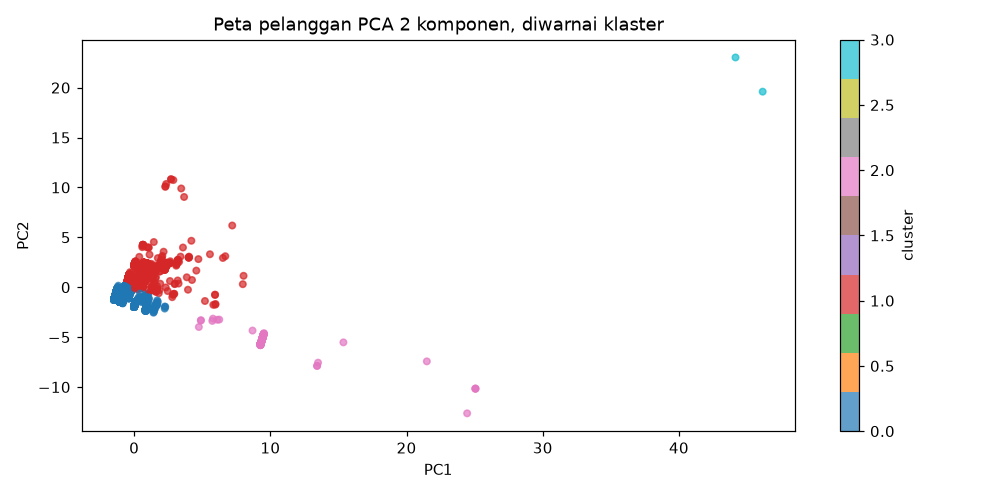

### cluster_size.png


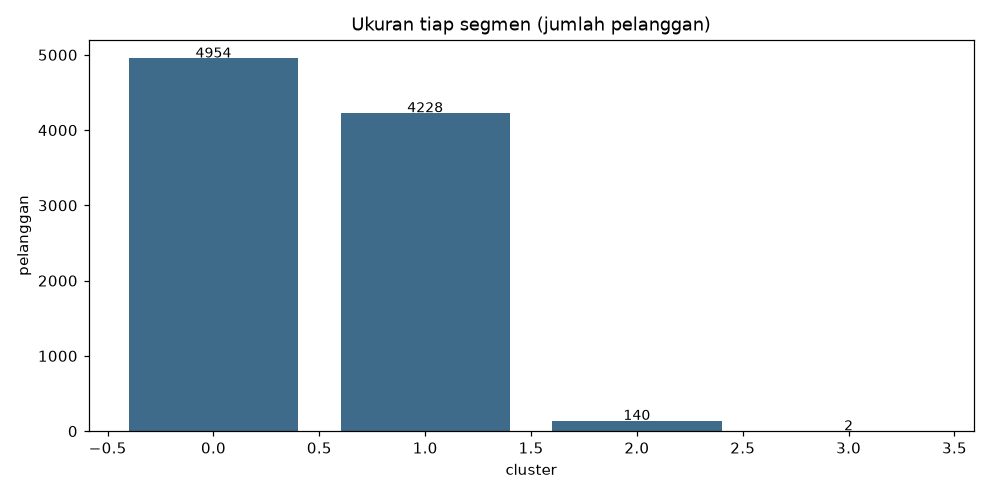

### cluster_profile.png


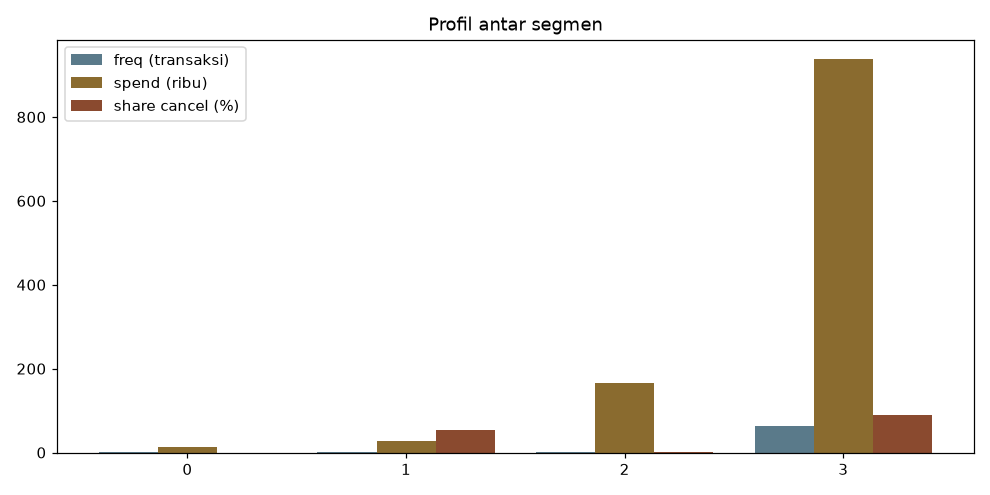

### rfm_scatter.png


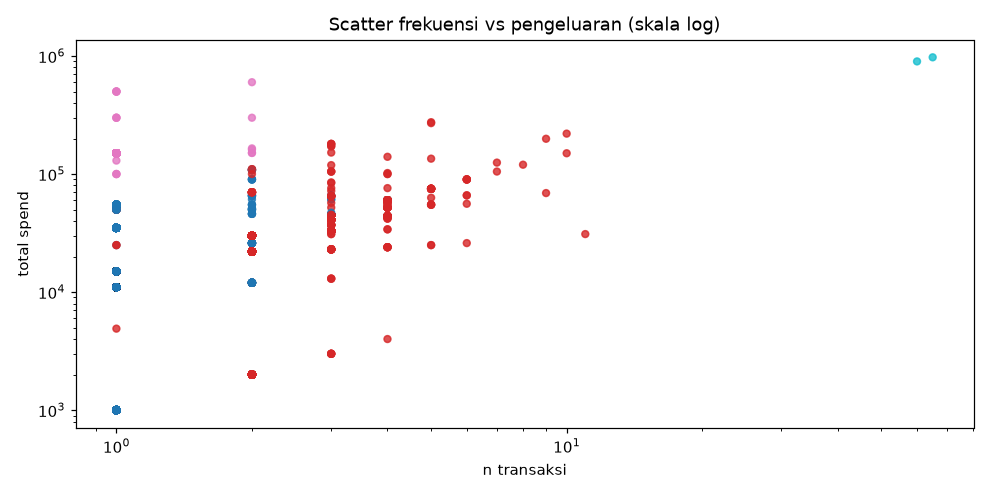

In [10]:
from IPython.display import Image
for name in ["elbow.png", "silhouette.png", "pca.png", "cluster_size.png",
             "cluster_profile.png", "rfm_scatter.png"]:
    print("###", name)
    display(Image(filename=os.path.join(OUT, name), width=620))

## Bab 4. Workflow Analisis Segmentasi Pelanggan

```mermaid
flowchart TD
    A["1. Tujuan bisnis: target, retensi, upsell"] --> B["2. Identifikasi basis dan variabel"]
    B --> C["3. Pembersihan data transaksi"]
    C --> D["4. Feature engineering per pelanggan (RFM + perilaku)"]
    D --> E["5. Normalisasi fitur"]
    E --> F["6. Evaluasi jumlah klaster (elbow, silhouette)"]
    F --> G["7. Clustering K-Means k=4"]
    G --> H["8. Profiling dan penamaan segmen"]
    H --> I["9. Validasi dan evaluasi"]
    I --> J["10. Rekomendasi strategi per segmen"]
    I -- "profil ambigu" --> E
```

**Checkpoint:**

- Setelah 3: 14.261 baris masuk, baris TESTLOCAL dikeluarkan.
- Setelah 4: 9.324 pelanggan dengan RFM dan fitur perilaku.
- Setelah 6: tabel elbow+silhouette tercatat, keputusan k=4 berdasar alasan.
- Setelah 8: jumlah segmen tervalidasi (jumlah pelanggan = 9.324).

## Bab 5. Kesimpulan, Rekomendasi, dan Keterbatasan

### Rekomendasi bisnis per segmen

1. **Pembeli Baru Aktif (4.954)**: dorong loyalitas dan perpanjangan; tawarkan paket durasi 60/90 hari dan cross-sell Norton 360; segmen belum pernah churn sehingga biaya akuisisi sudah terbayar.
2. **Pembeli Rentan Churn (4.228)**: prioritas retensi, pengingat kedaluwarsa, program perpanjangan dini, survei kepuasan; menahan 1% churn segmen ini nilainya besar karena frekuensi 2x.
3. **Pembeli Premium (140)**: layanan prioritas, paket keluarga/multi-device, jaga experience agar tidak pindah; nilai sangat tinggi per pelanggan.
4. **Pelaku Berulang Ekstrem (2)**: validasi akun dan kontrol anti-fraud (pola bulk di Digiflazz).

### Keterbatasan (disampaikan jujur)

1. Tidak ada data demografi dan geografis, sehingga segmen hanya berbasis perilaku.
2. Rentang waktu data terbatas (kebanyakan 2026), recency relatif terhadap akhir data, bukan waktu nyata.
3. `device_data` hanya terekam pada sebagian baris (1.628), dominasi Android bisa bias.
4. Dua pelanggan di segmen 3 berpotensi anomali/otomatisasi, bukan pelanggan individu.

### Isi folder

```
segmentasi/
├── segmentasi.ipynb          dokumen ini
├── segmentasi.db             fitur pelanggan + hasil segmen
├── sql/segment_schema.sql
├── scripts/                  etl_features, clustering, charts, run_segment
├── data/                     salinan CSV
├── assets/*.png              grafik
└── laporan/segmentasi.md     ringkasan
```